# 03 – Collaborative Filtering dựa trên láng giềng (kNN)

- **UserKNN**: user giống nhau thì thích phim giống nhau.
- **ItemKNN**: phim được cùng nhóm người dùng đánh giá giống nhau thì tương tự nhau.
- Độ tương đồng: **cosine** (rating thô) và **Pearson** (trừ trung bình trước khi cosine), có *shrinkage* để phạt cặp ít điểm chung.
- Dự đoán: $\hat r_{ui}=b_{ui}+\frac{\sum_j s_{ij}(r_{uj}-b_{uj})}{\sum_j |s_{ij}|}$ trên $k$ láng giềng (kNN-with-baseline).

Siêu tham số $k$ và loại similarity được **chọn trên tập validation** tách từ train, không dùng test, theo tiêu chí **NDCG@10** (chất lượng gợi ý Top-10); RMSE validation chỉ ghi lại để tham khảo.

---
### Bản chất từng mô hình

**Họ mô hình: memory-based CF (dựa trên bộ nhớ).** Không học tham số nào. "Huấn luyện" chỉ là tính sẵn ma trận độ tương đồng rồi ghi nhớ toàn bộ rating. Dự đoán = tham khảo ý kiến của những đối tượng giống nhất. Mô hình chỉ dùng rating, hoàn toàn không biết nội dung phim.

**Bước chung: baseline + phần dư.** Trước tiên ước lượng $b_{ui} = \mu + b_u + b_i$:
- $\mu$: trung bình toàn cục.
- $b_u$: độ "khó tính" của user.
- $b_i$: độ "được ưa chuộng" của phim.

Hai bias được giải xen kẽ bằng bình phương tối thiểu có điều chuẩn (`fit_biases`, $\lambda_i = 25$, $\lambda_u = 10$). kNN chỉ dự đoán **phần dư** $r_{uj} - b_{uj}$. Nhờ vậy láng giềng mang thông tin "thích hơn/kém hơn mức bình thường", không bị lẫn với việc user chấm cao hay chấm thấp nói chung.

**Độ tương đồng $s$:**
- **Cosine:** góc giữa hai vector rating thô. Ô chưa chấm bằng 0.
- **Pearson:** trừ trung bình của chính vector đó, chỉ ở các ô đã chấm, rồi mới tính cosine. Cách này loại bỏ thói quen chấm điểm cao hoặc thấp.
- **Shrinkage:** nhân $s$ với $\frac{n}{n + 10}$, với $n$ là số phần tử chung. Hai đối tượng chỉ trùng 1–2 phim dễ có $s$ cao một cách ngẫu nhiên, nên bị kéo về 0.
- Chỉ giữ láng giềng có $s > 0$ và giữ **top-k mỗi hàng**. Top-k này được chọn trên toàn bộ đối tượng, nên số láng giềng thực sự dùng được cho một ô (đã chấm phim/được user chấm) có thể ít hơn k.

**UserKNN:** "những người giống bạn thích phim này".
$$\hat r_{ui} = b_{ui} + \frac{\sum_{v \in N_k(u)} s_{uv}\,(r_{vi} - b_{vi})}{\sum_{v \in N_k(u)} |s_{uv}|}$$
Ma trận tương đồng có kích thước user × user (6040 × 6040). Gu của một người thay đổi và rất thưa: trung bình mỗi user chỉ chấm ~4% kho phim, nên độ tương đồng giữa các user kém ổn định.

**ItemKNN:** "bạn đã thích những phim giống phim này".
$$\hat r_{ui} = b_{ui} + \frac{\sum_{j \in N_k(i)} s_{ij}\,(r_{uj} - b_{uj})}{\sum_{j \in N_k(i)} |s_{ij}|}$$
Ma trận tương đồng có kích thước phim × phim (3706 × 3706). Mỗi phim có nhiều rating hơn mỗi user, nên độ tương đồng ổn định hơn. Đây là lý do ItemKNN thường tốt hơn UserKNN (và được Amazon dùng). Gợi ý cũng **giải thích được**: "vì bạn đã thích phim X".

**Điểm mạnh:**
- Trực quan, dễ giải thích.
- Không cần huấn luyện lặp.
- Thêm rating mới chỉ cần cập nhật ma trận tương đồng.

**Điểm yếu:**
- Tốn bộ nhớ $O(n^2)$.
- Không khái quát được qua các phim không có láng giềng chung.
- Mẫu số $\sum |s|$ tự triệt tiêu độ lớn của $s$. Khi chỉ có 1 láng giềng yếu thì phần dư của láng giềng đó được dùng nguyên vẹn, nên phim ít rating dễ bị đẩy điểm quá cao. Hệ quả là **RMSE và NDCG xung đột trực tiếp theo k**: k lớn (100–200) cho RMSE tốt nhất nhưng NDCG@10 gần 0; k nhỏ (5) cho NDCG@10 tốt nhất nhưng RMSE còn tệ hơn BiasBaseline. Khi chọn theo NDCG@10, kNN vẫn kém xa các mô hình implicit (xem notebook 08).

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import SELECT_METRIC, load_experiment, make_validation, run_model, save_metrics, validate
from src.evaluation.metrics import rmse

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
from src.models.knn_cf import UserKNN, ItemKNN
sub, val = make_validation(exp)
print(f"sub-train={len(sub):,}  validation={len(val):,}  | tiêu chí chọn: {SELECT_METRIC}")

sweep = []
for cls in (UserKNN, ItemKNN):
    for sim in ("cosine", "pearson"):
        for k in (5, 10, 20, 50, 100, 200):
            m = cls(k=k, similarity=sim).fit(sub, exp.user2idx, exp.item2idx, exp.movies)
            sweep.append(dict(Model=cls.__name__, similarity=sim, k=k, **validate(m, val)))
        print("done", cls.__name__, sim)
sweep = pd.DataFrame(sweep); sweep.round(4)

sub-train=720,105  validation=80,088  | tiêu chí chọn: ValNDCG@10


done UserKNN cosine


done UserKNN pearson


done ItemKNN cosine


done ItemKNN pearson


,Model,similarity,k,ValNDCG@10,ValRMSE
0,UserKNN,cosine,5,0.0199,1.0277
1,UserKNN,cosine,10,0.0077,0.9883
2,UserKNN,cosine,20,0.0027,0.9513
3,UserKNN,cosine,50,0.0011,0.9209
4,UserKNN,cosine,100,0.0005,0.9089
5,UserKNN,cosine,200,0.0002,0.9042
6,UserKNN,pearson,5,0.0203,1.0179
7,UserKNN,pearson,10,0.0086,0.9901
8,UserKNN,pearson,20,0.0031,0.9545
9,UserKNN,pearson,50,0.0011,0.9168


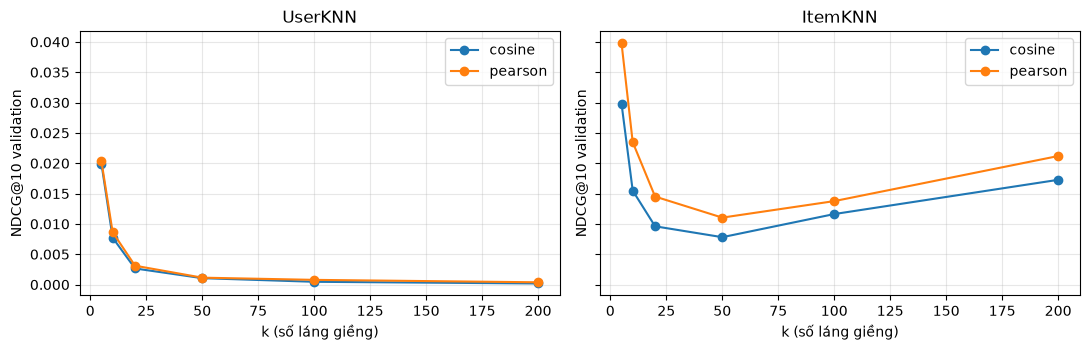

,Model,similarity,k,ValNDCG@10,ValRMSE
18,ItemKNN,pearson,5,0.039813,0.973081
6,UserKNN,pearson,5,0.020322,1.017854


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, name in zip(ax, ("UserKNN", "ItemKNN")):
    for sim, g in sweep[sweep.Model == name].groupby("similarity"):
        a.plot(g.k, g[SELECT_METRIC], marker="o", label=sim)
    a.set(title=name, xlabel="k (số láng giềng)", ylabel="NDCG@10 validation"); a.legend()
plt.tight_layout(); plt.savefig(FIG / "knn_k_sweep.png"); plt.show()
best = sweep.loc[sweep.groupby("Model")[SELECT_METRIC].idxmax()]; best

## Huấn luyện lại trên toàn bộ train với cấu hình tốt nhất và đánh giá trên test

In [4]:
rows = []
for _, b in best.iterrows():
    cls = UserKNN if b.Model == "UserKNN" else ItemKNN
    rows.append(run_model(cls(k=int(b.k), similarity=b.similarity), exp)); print("done", rows[-1]["Model"])
res = pd.DataFrame(rows)

done ItemKNN(k=5,pearson)


done UserKNN(k=5,pearson)


In [5]:
res[['Model', 'RMSE', 'MAE', 'Precision@10', 'Recall@10', 'NDCG@10', 'HitRate@10', 'Coverage@20', 'FitTime_s']].round(4)

,Model,RMSE,MAE,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,FitTime_s
0,"ItemKNN(k=5,pearson)",0.9631,0.7308,0.0581,0.0487,0.0668,0.4161,0.8486,0.6714
1,"UserKNN(k=5,pearson)",1.0084,0.7790,0.0362,0.0249,0.0389,0.2733,0.6865,0.8748


In [6]:
save_metrics(res.assign(Family="Collaborative (kNN)"), "knn")

WindowsPath('D:/HỌC/kì 7/Machine Learning/machine_learning/outputs/metrics/knn.csv')